# Biography benchmark of 50: polity validation

Fifty of the 300 benchmark individuals (a sixth of each region, `building_scripts/benchmark50_texts.py`), with their biography downloaded from a scholarly dictionary. Five Claude Code agents (claude-opus-5-5) read the texts blind to Cultura and extracted, for the early, active and late stage, the most granular place mentioned, with word-for-word extracts and an English translation. The prompt is saved in `scripts/5-annotations/prompts/biography_polity_extraction.md`.

Each place is mapped to the Cliopatria polity holding it over the years Cultura gives the stage (smallest polity of the hierarchy). A stage is validated when a benchmark polity matches a Cultura polity directly or through a parent polity, and is compared only when both sides have a polity (`building_scripts/biography_example_validation.py --benchmark50`).

In [1]:
import json
import sys
from pathlib import Path

import polars as pl

ROOT = Path.cwd().resolve()
while not (ROOT / ".git").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "notebooks" / "notebooks_analysis"))
from style import show_table

FOLDER = ROOT / "scripts" / "5-annotations" / "benchmark" / "benchmark50"
STAGES = {"early": "Early life", "active": "Active life", "late": "Late life"}
texts = json.loads((FOLDER / "benchmark50_texts.json").read_text(encoding="utf-8"))
regions = pl.DataFrame([{"qid": person["qid"], "region": person["claude_estimated_region"], "characters": len(person["text"])} for person in texts])
stages = pl.read_csv(FOLDER / "benchmark50.tsv", separator="\t").join(regions, on="qid")
compared = stages.filter(pl.col("compared"))
print(f"{stages['qid'].n_unique()} individuals, {len(stages)} stages, {len(compared)} compared, {compared['validated'].sum()} validated")

50 individuals, 150 stages, 117 compared, 103 validated


## The sample

Individuals per region and biography dictionary.

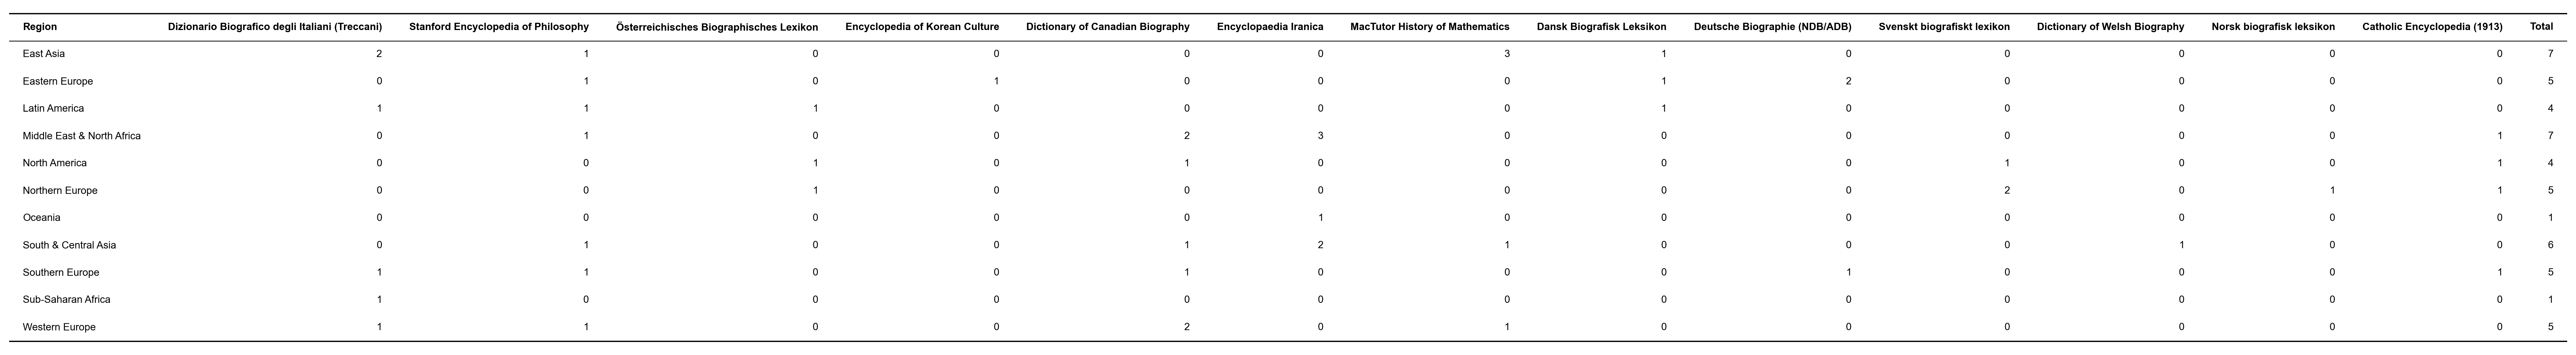

In [2]:
sample = (stages.unique("qid").group_by("region", "dictionary_name").len()
          .pivot(on="dictionary_name", index="region", values="len").fill_null(0).sort("region"))
sample = sample.with_columns(Total=pl.sum_horizontal(pl.exclude("region"))).rename({"region": "Region"})
show_table(sample, font_size=8)

## Which stages could be compared

A stage is left out when the biography gives no place, when Cultura has no polity for it, or when the place falls in no Cliopatria polity those years.

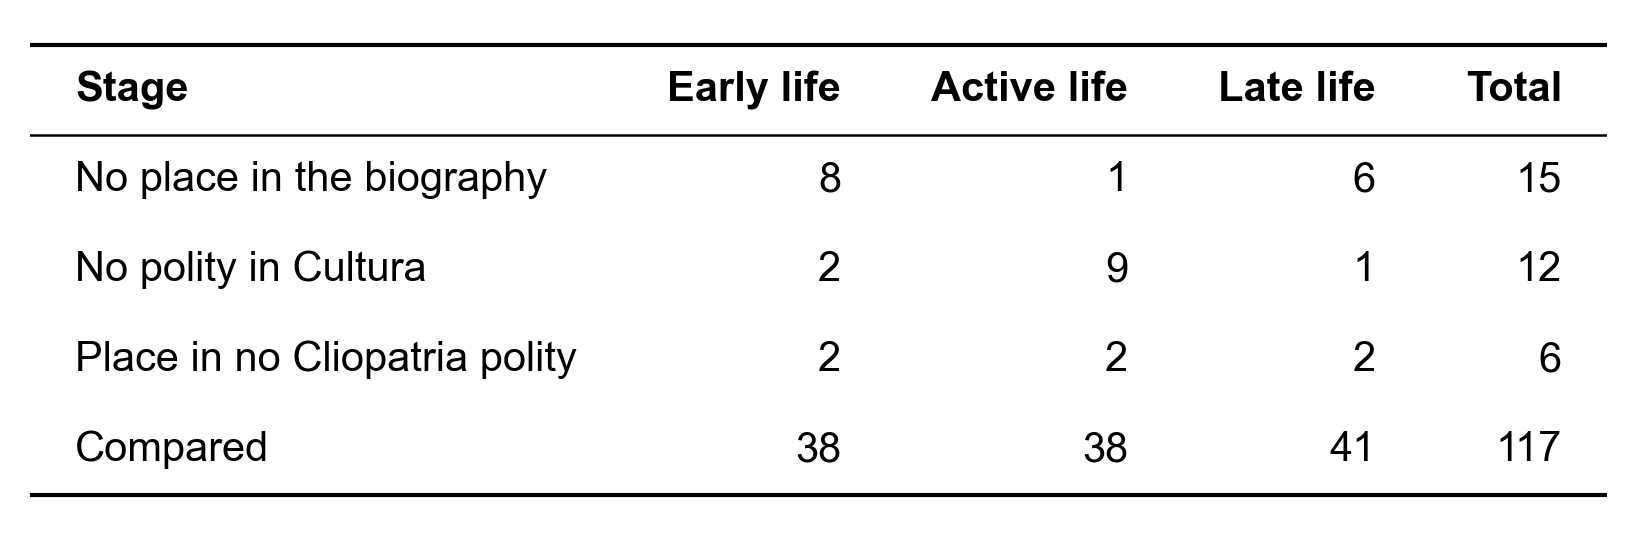

In [3]:
reason = (pl.when(pl.col("compared")).then(pl.lit("Compared"))
          .when(pl.col("benchmark_place").is_null()).then(pl.lit("No place in the biography"))
          .when(pl.col("cultura_polity").is_null()).then(pl.lit("No polity in Cultura"))
          .otherwise(pl.lit("Place in no Cliopatria polity")))
coverage = (stages.with_columns(reason=reason).group_by("reason", "stage").len()
            .pivot(on="stage", index="reason", values="len").fill_null(0)
            .select(pl.col("reason").alias("Stage"), *[pl.col(stage).alias(name) for stage, name in STAGES.items()]))
show_table(coverage.with_columns(Total=pl.sum_horizontal(list(STAGES.values()))), font_size=10)

## Accuracy

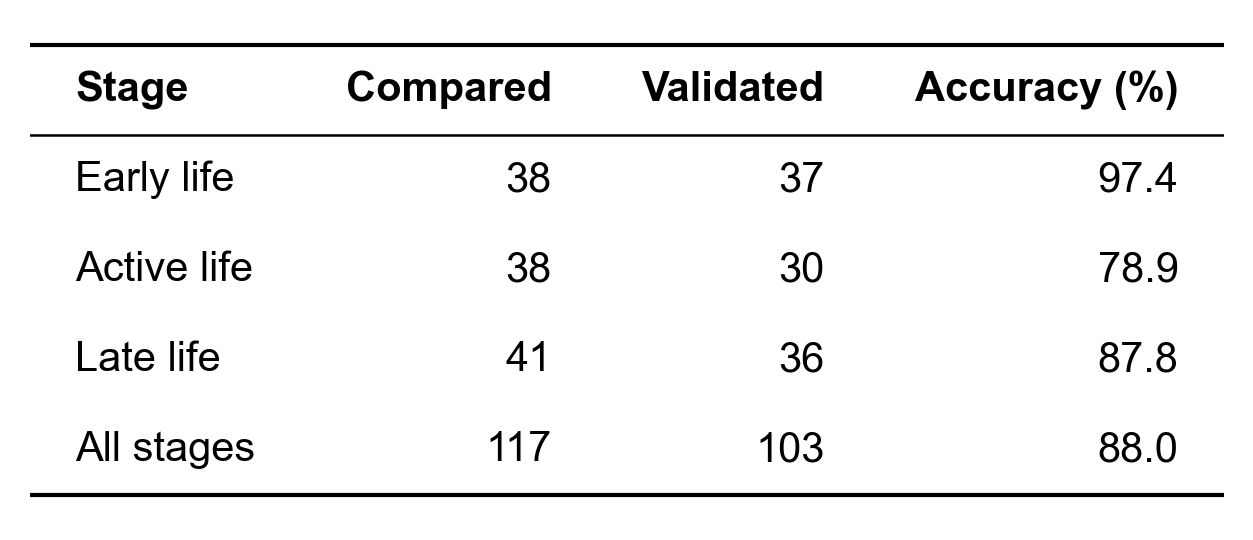

In [4]:
def accuracy(frame, by):
    return (frame.group_by(by).agg(Compared=pl.len(), Validated=pl.col("validated").sum())
            .with_columns(**{"Accuracy (%)": (100 * pl.col("Validated") / pl.col("Compared")).round(1)}))

by_stage = accuracy(compared, "stage").sort(pl.col("stage").cast(pl.Enum(list(STAGES)))).with_columns(pl.col("stage").replace(STAGES))
total = accuracy(compared.with_columns(stage=pl.lit("All stages")), "stage")
show_table(pl.concat([by_stage, total]).rename({"stage": "Stage"}), decimals=1, font_size=10)

Accuracy by the agents' confidence in the extracted place: the higher the confidence, the more often the stage is validated.

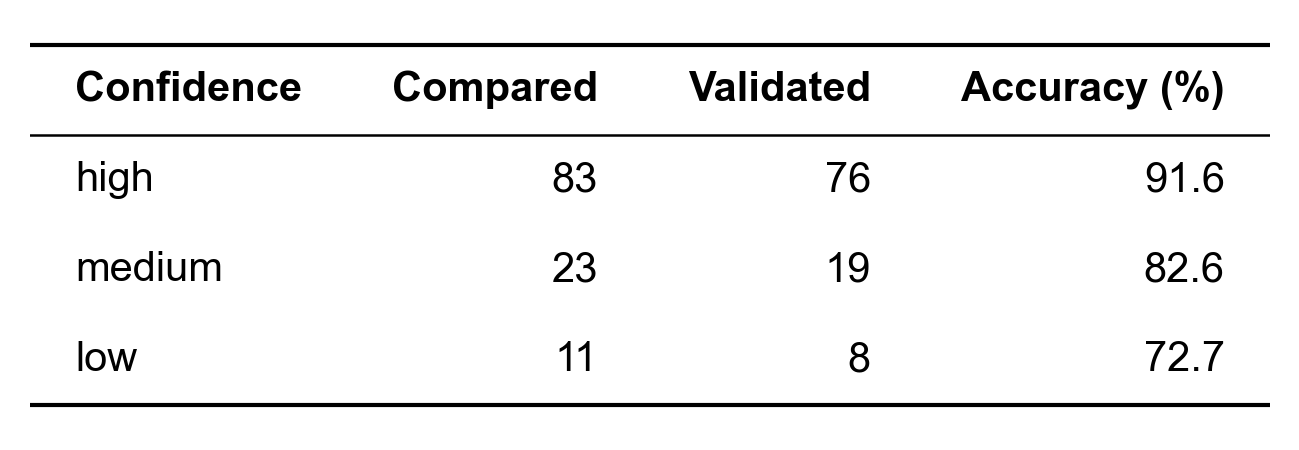

In [5]:
by_confidence = accuracy(compared, "benchmark_confidence").sort(pl.col("benchmark_confidence").cast(pl.Enum(["high", "medium", "low"])))
show_table(by_confidence.rename({"benchmark_confidence": "Confidence"}), decimals=1, font_size=10)

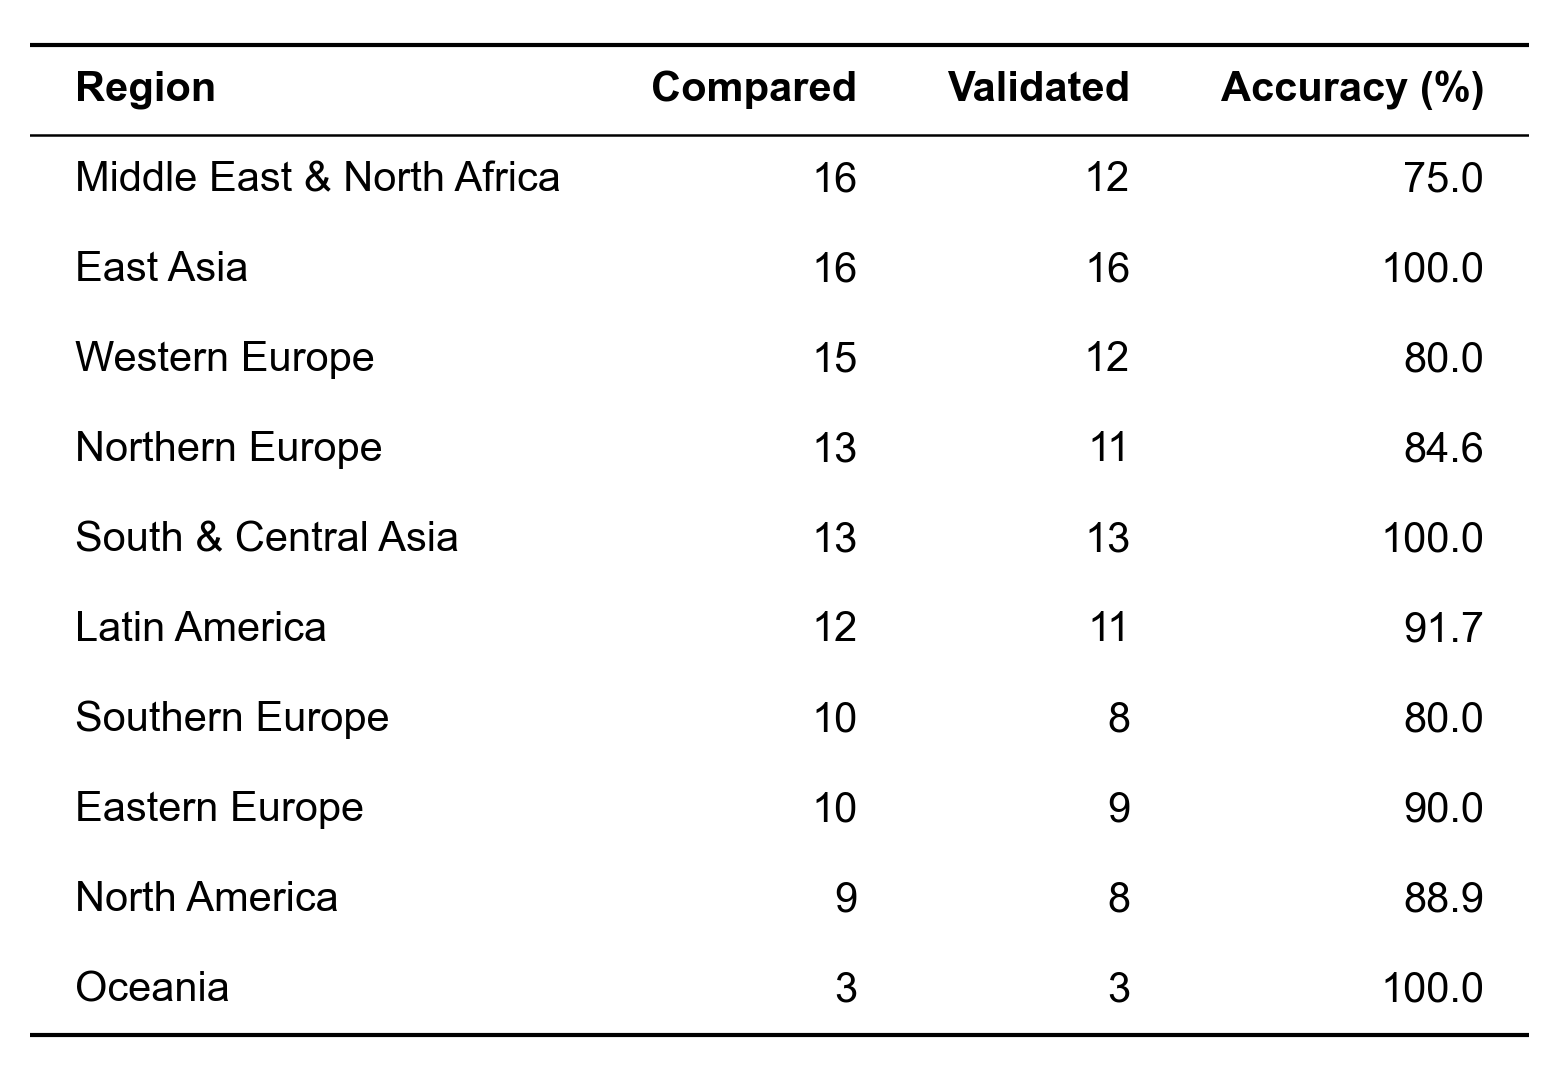

In [6]:
by_region = accuracy(compared, "region").sort("Compared", descending=True)
show_table(by_region.rename({"region": "Region"}), decimals=1, font_size=10)

## Checking the mismatches

Every stage not validated, read against the biography. The cause is my review of each case.

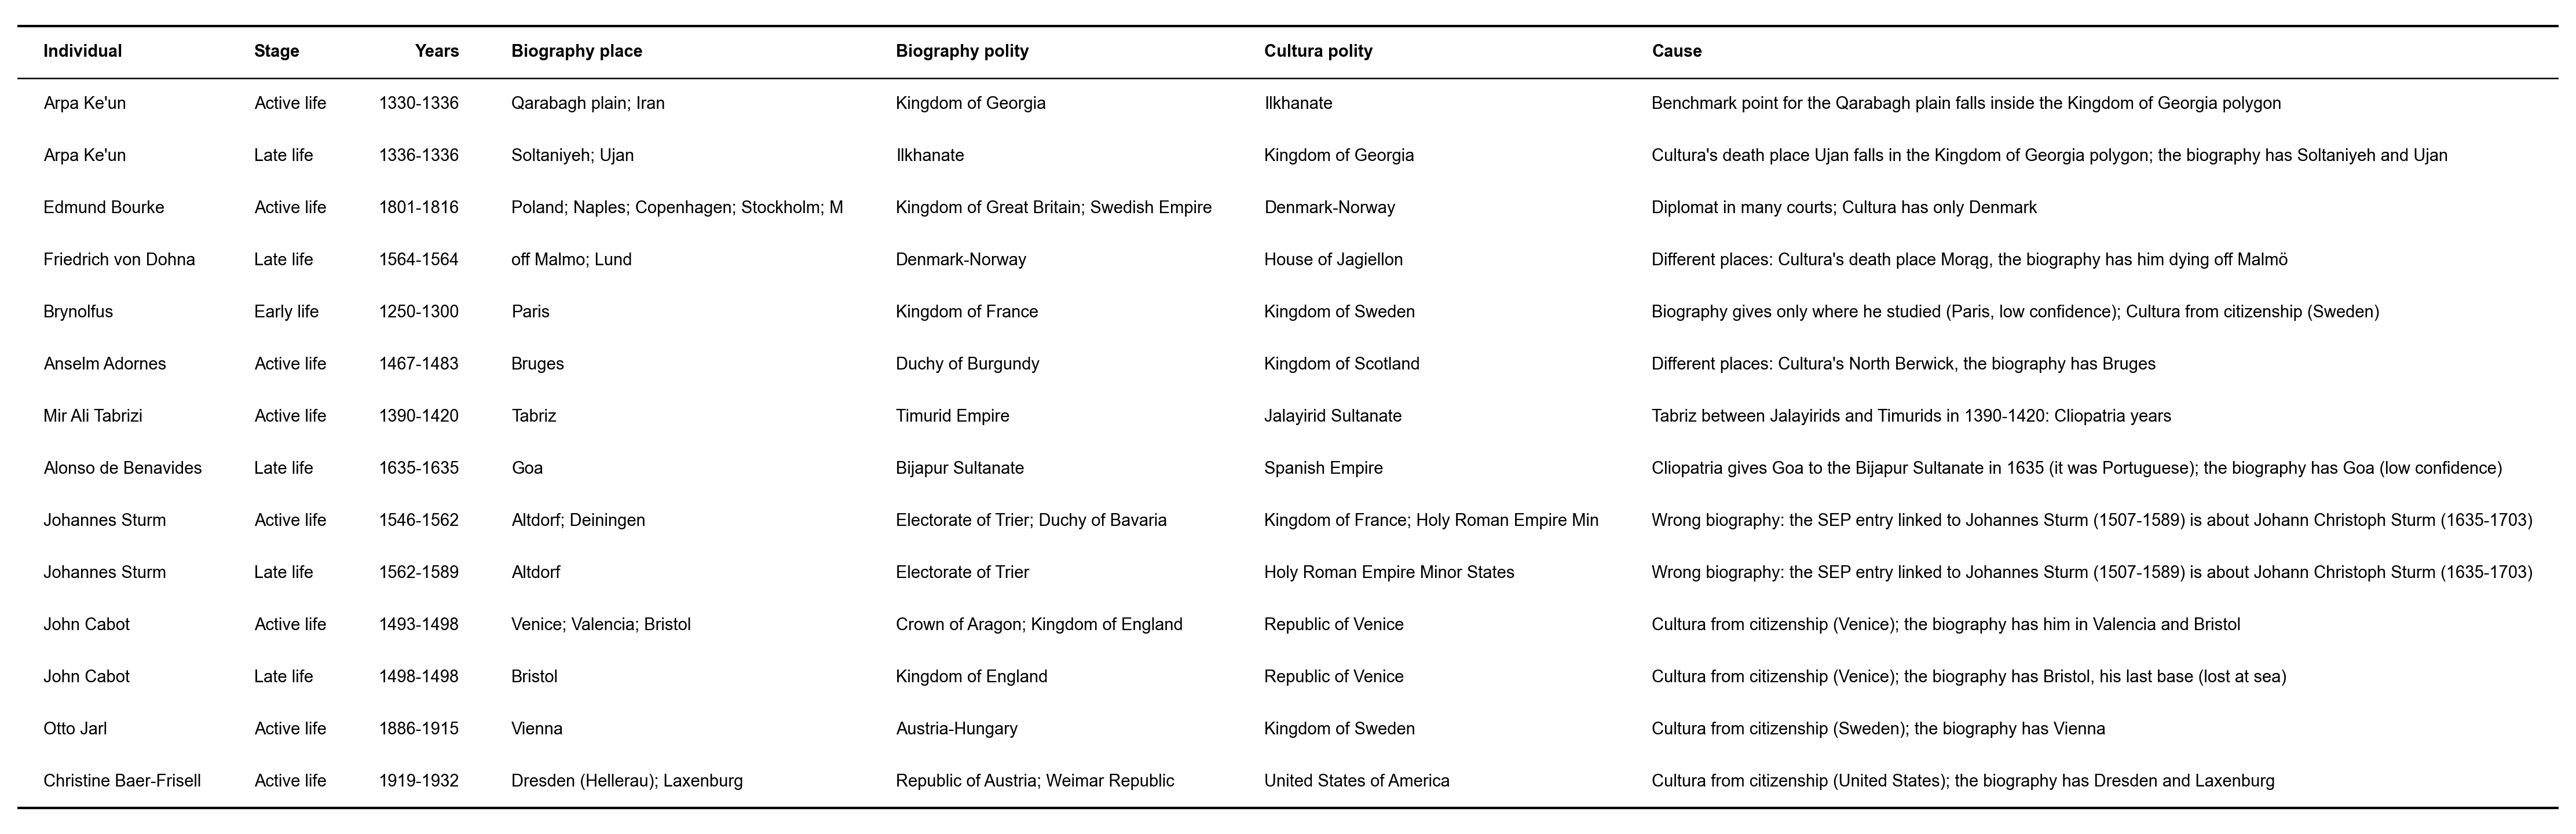

In [7]:
CAUSES = {
    ("Q66382", "active"): "Wrong biography: the SEP entry linked to Johannes Sturm (1507-1589) is about Johann Christoph Sturm (1635-1703)",
    ("Q66382", "late"): "Wrong biography: the SEP entry linked to Johannes Sturm (1507-1589) is about Johann Christoph Sturm (1635-1703)",
    ("Q85642", "active"): "Cultura from citizenship (Venice); the biography has him in Valencia and Bristol",
    ("Q85642", "late"): "Cultura from citizenship (Venice); the biography has Bristol, his last base (lost at sea)",
    ("Q874893", "active"): "Cultura from citizenship (Sweden); the biography has Vienna",
    ("Q61193907", "active"): "Cultura from citizenship (United States); the biography has Dresden and Laxenburg",
    ("Q332860", "early"): "Biography gives only where he studied (Paris, low confidence); Cultura from citizenship (Sweden)",
    ("Q5623141", "late"): "Different places: Cultura's death place Morąg, the biography has him dying off Malmö",
    ("Q2795465", "active"): "Different places: Cultura's North Berwick, the biography has Bruges",
    ("Q5339306", "active"): "Diplomat in many courts; Cultura has only Denmark",
    ("Q698603", "active"): "Benchmark point for the Qarabagh plain falls inside the Kingdom of Georgia polygon",
    ("Q698603", "late"): "Cultura's death place Ujan falls in the Kingdom of Georgia polygon; the biography has Soltaniyeh and Ujan",
    ("Q4115137", "active"): "Tabriz between Jalayirids and Timurids in 1390-1420: Cliopatria years",
    ("Q4734500", "late"): "Cliopatria gives Goa to the Bijapur Sultanate in 1635 (it was Portuguese); the biography has Goa (low confidence)",
}
mismatches = (stages.filter(pl.col("validated") == False)
              .with_columns(cause=pl.struct("qid", "stage").map_elements(lambda row: CAUSES.get((row["qid"], row["stage"]), "unchecked"), return_dtype=pl.String),
                            years=pl.col("cultura_stage_start_year").cast(pl.String) + "-" + pl.col("cultura_stage_end_year").cast(pl.String))
              .select(pl.col("label").alias("Individual"), pl.col("stage").replace(STAGES).alias("Stage"), pl.col("years").alias("Years"),
                      pl.col("benchmark_place").alias("Biography place"), pl.col("benchmark_polity").alias("Biography polity"),
                      pl.col("cultura_polity").alias("Cultura polity"), pl.col("cause").alias("Cause")))
assert "unchecked" not in mismatches["Cause"].to_list()
show_table(mismatches.with_columns(pl.col("Biography place", "Biography polity", "Cultura polity").str.slice(0, 40)), font_size=7)

Grouped by cause: only part of the mismatches are errors of Cultura; the others come from a wrong biography link or from the Cliopatria polygons.

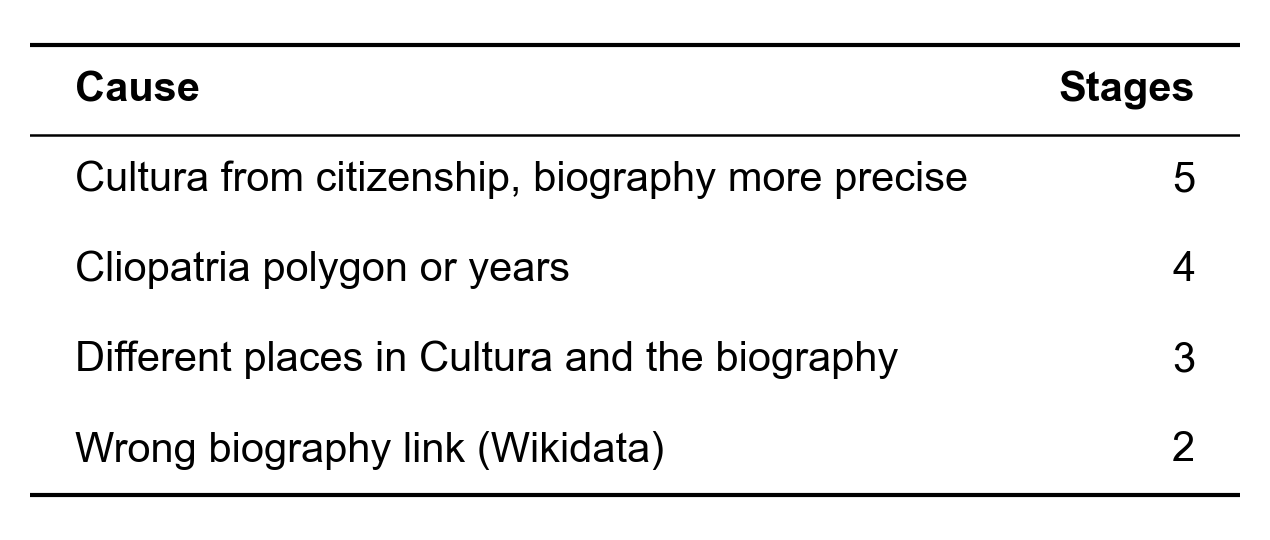

In [8]:
GROUPS = {"Wrong biography": "Wrong biography link (Wikidata)", "Cultura from citizenship": "Cultura from citizenship, biography more precise",
          "Biography gives only": "Cultura from citizenship, biography more precise", "Different places": "Different places in Cultura and the biography",
          "Diplomat": "Different places in Cultura and the biography", "Benchmark point": "Cliopatria polygon or years", "Cultura's death place Ujan": "Cliopatria polygon or years",
          "Tabriz": "Cliopatria polygon or years", "Cliopatria gives": "Cliopatria polygon or years"}
group = pl.col("Cause").map_elements(lambda cause: next(name for start, name in GROUPS.items() if cause.startswith(start)), return_dtype=pl.String)
show_table(mismatches.group_by(group.alias("Cause")).len().rename({"len": "Stages"}).sort("Stages", descending=True), font_size=10)

## Robustness

With multi-place stages, one matching polity is enough. Restricting to stages where the biography gives a single place, and leaving out the wrongly linked biography (Johannes Sturm):

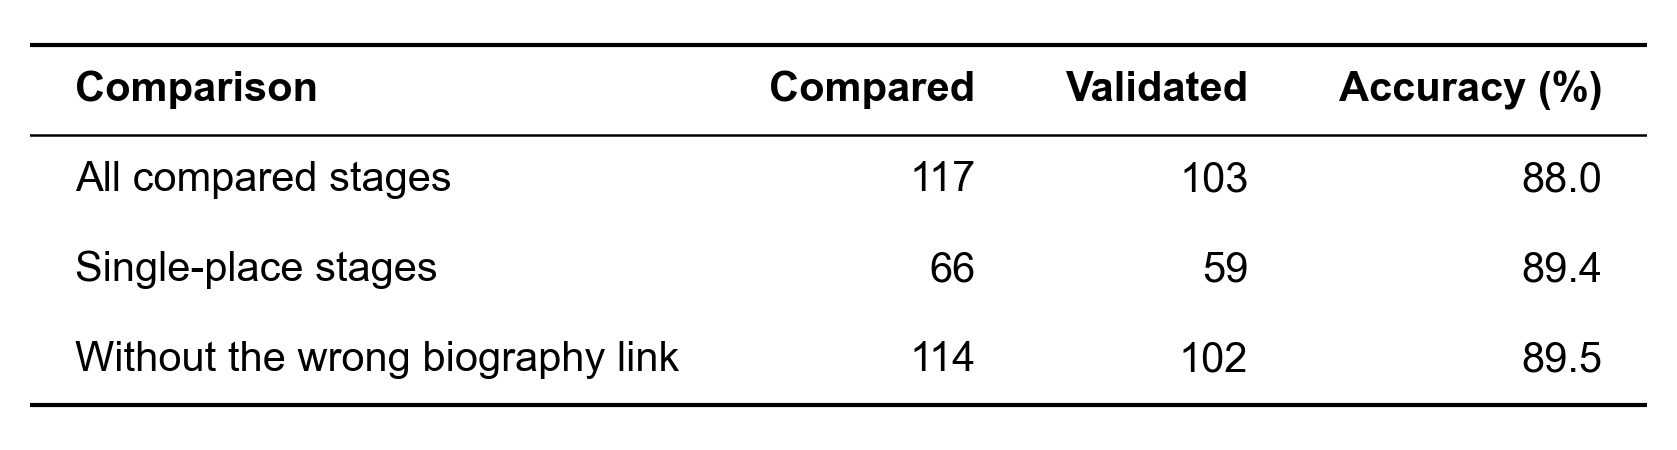

In [9]:
checks = pl.DataFrame({
    "Comparison": ["All compared stages", "Single-place stages", "Without the wrong biography link"],
    "Compared": [len(compared), compared.filter(~pl.col("benchmark_place").str.contains(";")).height, compared.filter(pl.col("qid") != "Q66382").height],
    "Validated": [compared["validated"].sum(), compared.filter(~pl.col("benchmark_place").str.contains(";"))["validated"].sum(), compared.filter(pl.col("qid") != "Q66382")["validated"].sum()],
}).with_columns(**{"Accuracy (%)": (100 * pl.col("Validated") / pl.col("Compared")).round(1)})
show_table(checks, decimals=1, font_size=10)

## Extraction cost

Tokens reported by Claude Code for each of the five agents (the main session's coordination, download and comparison are not included).

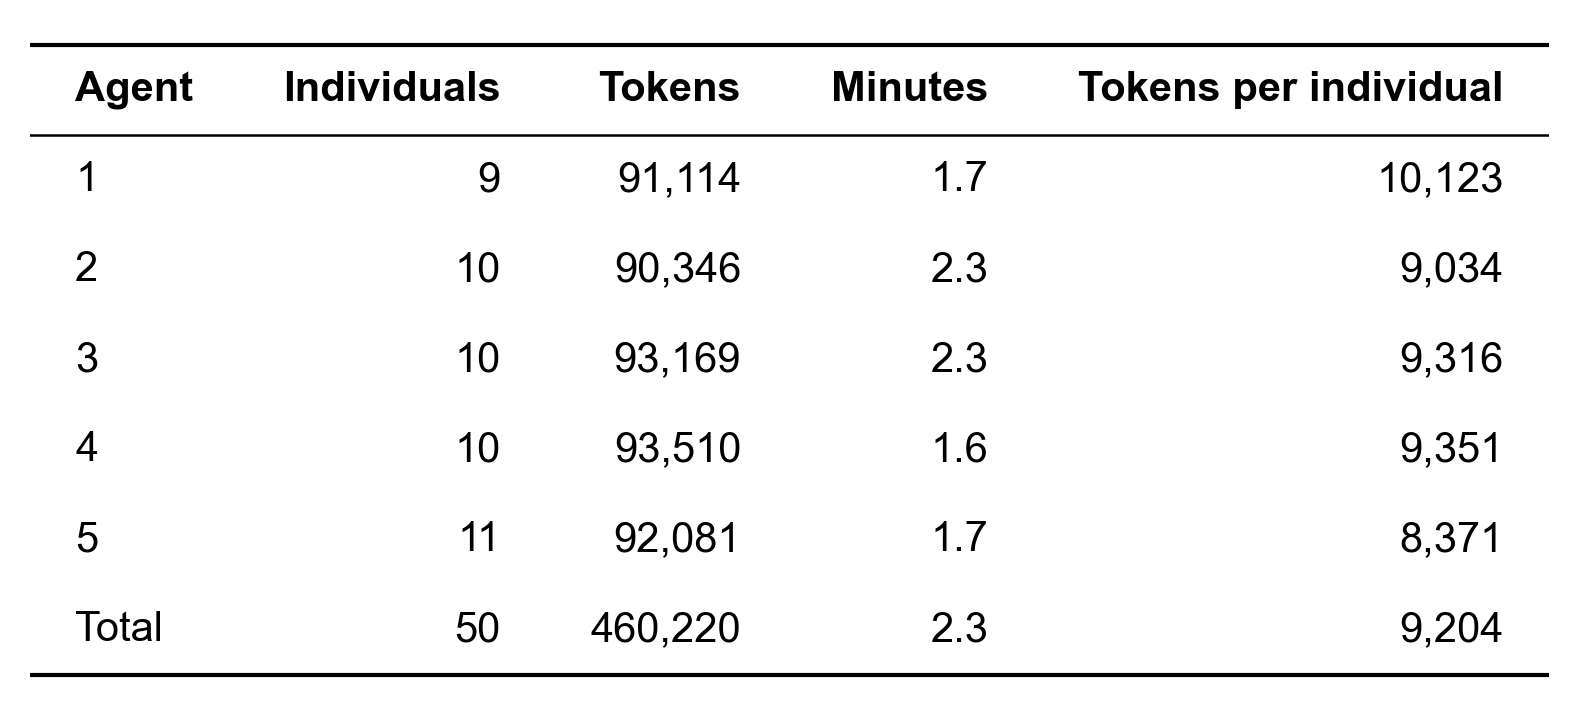

In [10]:
AGENTS = pl.DataFrame({"Agent": [1, 2, 3, 4, 5], "Individuals": [9, 10, 10, 10, 11],
                       "Tokens": [91_114, 90_346, 93_169, 93_510, 92_081], "Minutes": [1.7, 2.3, 2.3, 1.6, 1.7]})
cost = pl.concat([AGENTS.with_columns(pl.col("Agent").cast(pl.String)),
                  AGENTS.select(pl.lit("Total").alias("Agent"), pl.col("Individuals").sum(), pl.col("Tokens").sum(), pl.col("Minutes").max())])
show_table(cost.with_columns(**{"Tokens per individual": pl.col("Tokens") // pl.col("Individuals")}), decimals=1, font_size=10)